# <center> Исследовательский анализ данных </center>

### Описание данных

Каждая строка датасета соответствует одному наблюдению о клиенте
страховой компании.

| Признак | Описание |
|---|---|
| id | Идентификатор наблюдения |
| Gender | Пол клиента |
| Age | Возраст клиента |
| Driving_License | Наличие водительского удостоверения (0 — нет, 1 — да) |
| Region_Code | Код региона проживания клиента |
| Previously_Insured | Наличие ранее оформленной страховки автомобиля (0 — нет, 1 — да) |
| Vehicle_Age | Возраст автомобиля |
| Vehicle_Damage | Наличие повреждений автомобиля в прошлом |
| Annual_Premium | Размер годовой страховой премии |
| Policy_Sales_Channel | Код канала продажи страхового продукта |
| Vintage | Количество дней, в течение которых клиент обслуживается в компании |
| Response | Целевая переменная (0 — клиент не купил страховку, 1 — купил) |

### Типы признаков

- Числовые: Age, Annual_Premium, Vintage.
- Категориальные: Gender, Region_Code, Vehicle_Age, Policy_Sales_Channel.
- Бинарные: Driving_License, Previously_Insured, Vehicle_Damage.
- Идентификатор: id.
- Целевая переменная: Response.

## <a class="anchor" id="9th"></a> Навигация
* [1. Знакомство с данными и предобработка](#1st)
* [2. Анализ целевой переменной](#2th)
* [3. Анализ числовых переменных](#3th)
* [4. Анализ категориальных переменных](#4th)
* [5. Корреляционный анализ и взаимосвязь признаков](#5th)
* [6. Проверка статистических гипотез](#6th)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st
from scipy.stats.contingency import association

## <a class="anchor" id="1st"></a> 1. Знакомство с данными и предобработка

In [3]:
df = pd.read_csv('train.csv')
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,0,Male,21,1,35.0,0,1-2 Year,Yes,65101.0,124.0,187,0
1,1,Male,43,1,28.0,0,> 2 Years,Yes,58911.0,26.0,288,1
2,2,Female,25,1,14.0,1,< 1 Year,No,38043.0,152.0,254,0
3,3,Female,35,1,1.0,0,1-2 Year,Yes,2630.0,156.0,76,0
4,4,Female,36,1,15.0,1,1-2 Year,No,31951.0,152.0,294,0


In [4]:
# переведем заголовки в нижний регистр
df.columns = df.columns.str.lower()

In [5]:
# проверим, есть ли в заголовках русские буквы
columns = df.keys().tolist()

for column in columns:
    print(column.isascii())

True
True
True
True
True
True
True
True
True
True
True
True


In [6]:
# проверим размер датасета
df.shape

(11504798, 12)

In [7]:
# отделим последний миллион данных на тест
test = df.iloc[-1_000_000:]
df = df.iloc[:-1_000_000]

print('Основная выборка:', df.shape)
print('Тестовая выборка:', test.shape)

Основная выборка: (10504798, 12)
Тестовая выборка: (1000000, 12)


In [15]:
# основная информация
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10504798 entries, 0 to 10504797
Data columns (total 12 columns):
 #   Column                Dtype  
---  ------                -----  
 0   id                    int64  
 1   gender                str    
 2   age                   int64  
 3   driving_license       int64  
 4   region_code           float64
 5   previously_insured    int64  
 6   vehicle_age           str    
 7   vehicle_damage        str    
 8   annual_premium        float64
 9   policy_sales_channel  float64
 10  vintage               int64  
 11  response              int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 961.7 MB


In [8]:
# некоторые категориальные данные переведем в object
df['region_code'] = df['region_code'].astype('object')
df['policy_sales_channel'] = df['policy_sales_channel'].astype('object')

In [17]:
# проверим пропуски
df.isna().sum()

id                      0
gender                  0
age                     0
driving_license         0
region_code             0
previously_insured      0
vehicle_age             0
vehicle_damage          0
annual_premium          0
policy_sales_channel    0
vintage                 0
response                0
dtype: int64

In [18]:
# проверим полные дубликаты
df.duplicated().sum()

np.int64(0)

In [19]:
# проверим дубли по пину клиента
df['id'].duplicated().sum()

np.int64(0)

In [20]:
# посмотрим на описательные статистики
df.describe().round(2)

,id,age,driving_license,previously_insured,annual_premium,vintage,response
count,10504798.00,10504798.00,10504798.00,10504798.00,10504798.00,10504798.00,10504798.00
mean,5252398.50,38.38,1.00,0.46,30460.50,163.90,0.12
std,3032474.12,14.99,0.04,0.50,16463.31,79.98,0.33
min,0.00,20.00,0.00,0.00,2630.00,10.00,0.00
25%,2626199.25,24.00,1.00,0.00,25276.00,99.00,0.00
50%,5252398.50,36.00,1.00,0.00,31822.00,166.00,0.00
75%,7878597.75,49.00,1.00,1.00,39450.00,232.00,0.00
max,10504797.00,85.00,1.00,1.00,540165.00,299.00,1.00


In [21]:
# посмотрим число уникальных значений
df.nunique()

id                      10504798
gender                         2
age                           66
driving_license                2
region_code                   53
previously_insured             2
vehicle_age                    3
vehicle_damage                 2
annual_premium             51345
policy_sales_channel         152
vintage                      290
response                       2
dtype: int64

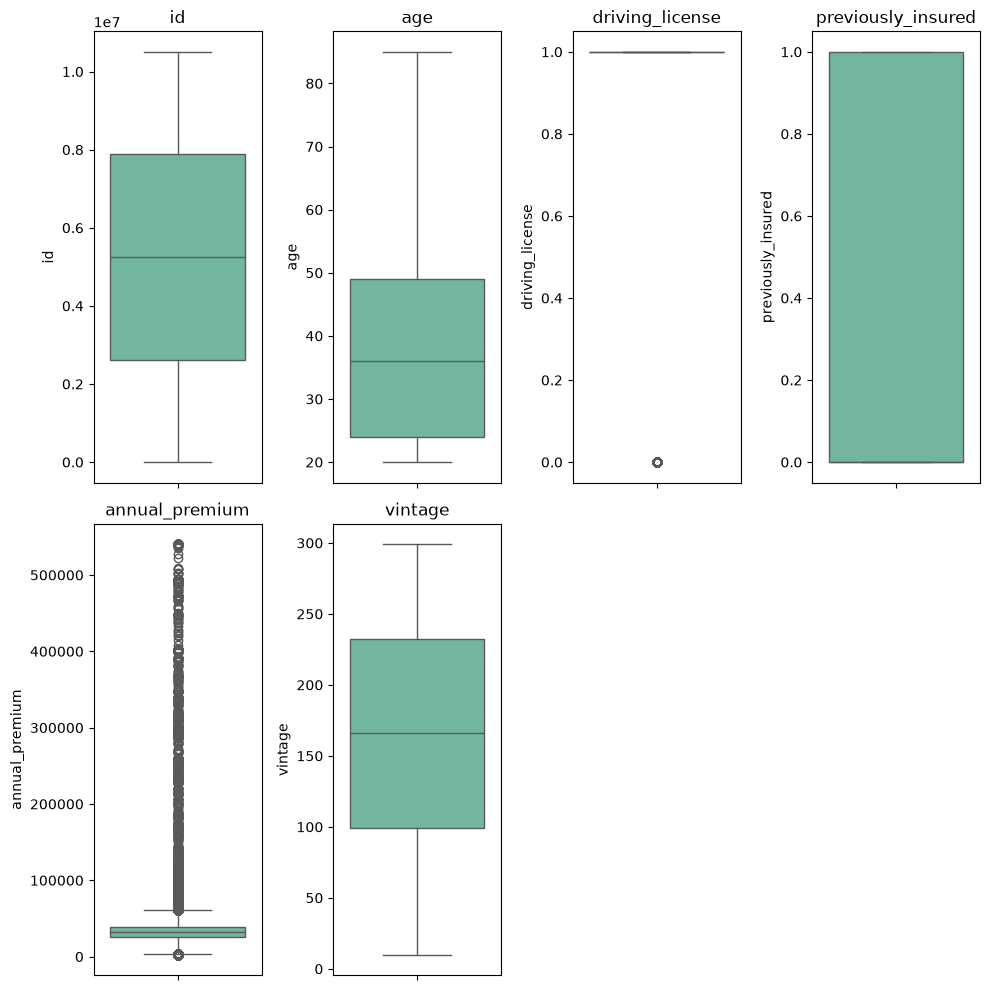

In [22]:
#построим общие боксплоты, может найдем какие-то аномалии
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

numeric_columns = numeric_columns[:-1]

plt.figure(figsize=(10, 10))
sns.set_palette('Set2')

num_columns = len(numeric_columns)

n_rows = (num_columns // 4) + (num_columns % 4 > 0)  
n_cols = min(num_columns, 4)  

for i, column in enumerate(numeric_columns):
    plt.subplot(n_rows, n_cols, i + 1) 
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

### Вывод:<br>
1. Последний миллион данных выделили на тест
2. Проблем с типами данных нет, категориальные данные перевели в object
3. Названия колонах на латинице, русских букв нет
4. Пропусков, полных дублей, дублей по айди нет
5. Явных аномалий не обнаружено

[Вернуться к навигации](#9th)

## <a class="anchor" id="2nd"></a> 2. Анализ целевой переменной

In [23]:
df['response'].value_counts(), df['response'].value_counts(normalize=True)*100

(response
 0    9212446
 1    1292352
 Name: count, dtype: int64,
 response
 0    87.697507
 1    12.302493
 Name: proportion, dtype: float64)

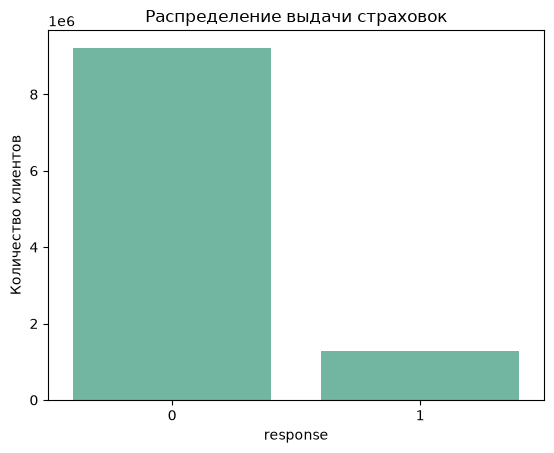

In [24]:
sns.countplot(data=df, x='response')

plt.title('Распределение выдачи страховок')
plt.xlabel('response')
plt.ylabel('Количество клиентов')
plt.show()

### Вывод: <br>
1. Наблюдаем сильный дисбаланс - страховку купило только 12% клиентов (1 292 352 человек)
2. В качестве метрики оценки качества модели не стоит смотреть на accuracy 

[Вернуться к навигации](#9th)

## <a class="anchor" id="3rd"></a> 3. Анализ числовых переменных

In [25]:
num_cols = ['age', 'annual_premium', 'vintage']
# возраст
# размер годовой страховой премии
# кол-во дней, в течение которых клиент обслуживается в компании

In [26]:
df[num_cols].describe().round(2)

,age,annual_premium,vintage
count,10504798.00,10504798.00,10504798.00
mean,38.38,30460.50,163.90
std,14.99,16463.31,79.98
min,20.00,2630.00,10.00
25%,24.00,25276.00,99.00
50%,36.00,31822.00,166.00
75%,49.00,39450.00,232.00
max,85.00,540165.00,299.00


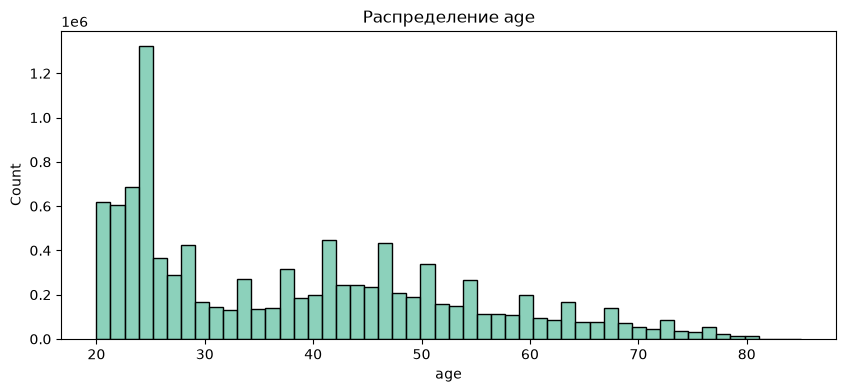

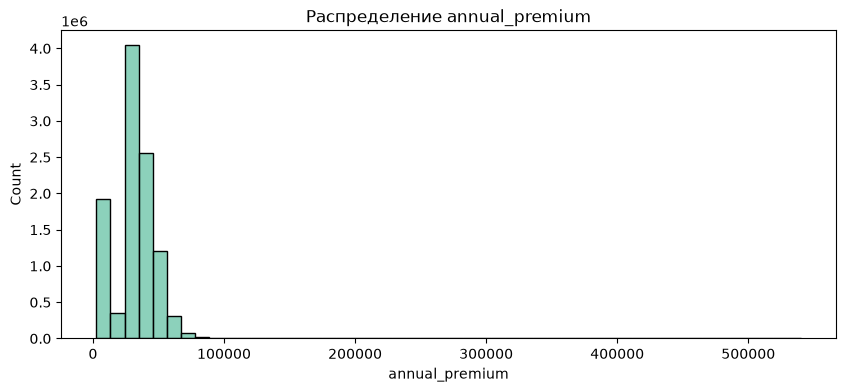

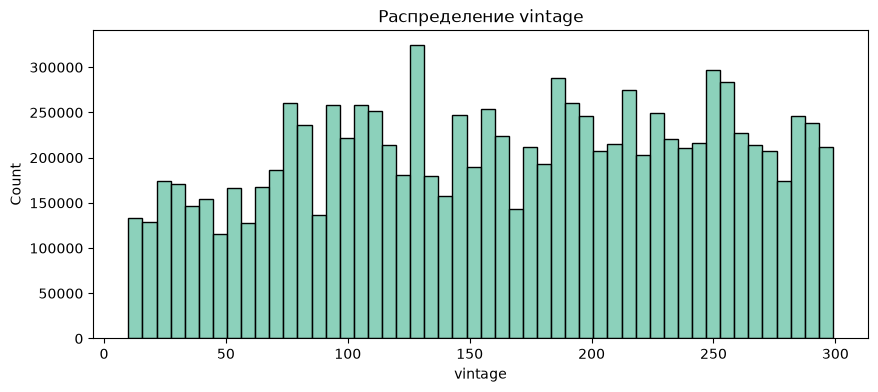

In [27]:
for col in num_cols:
    plt.figure(figsize=(10, 4))
    sns.histplot(data=df, x=col, bins=50)
    plt.title(f'Распределение {col}')
    plt.show()

In [28]:
df[num_cols].skew()

age               0.637432
annual_premium    0.799949
vintage          -0.108161
dtype: float64

Наблюдаем правостороннюю асимметрию у age и annual_premium, а также незначительную левостороннюю ассимметрию у vintage

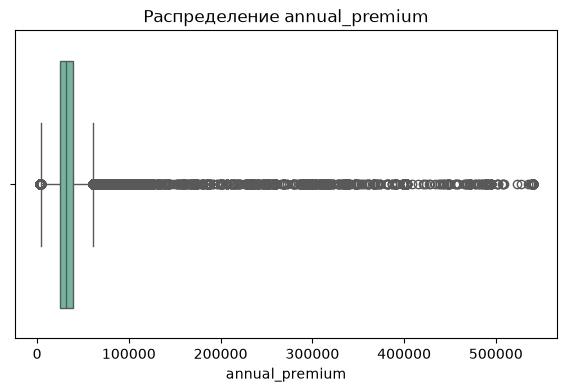

In [29]:
# посмотрим подробнее на боксплот размера страховой премии
plt.figure(figsize=(7, 4))
sns.boxplot(x=df['annual_premium'])
plt.title('Распределение annual_premium')
plt.xlabel('annual_premium')
plt.show()

Переменная annual_premium имеет длинный хвост справа (правосторонняя ассимметрия) и содержит много выбросов. Возможно имеет смысл взять 0.99 квантиль, чтобы поведение единичных клиентов с большой страховкой не давало перекосов по метрикам. Посмотрим, сколько из таких клиентов взяли страховку

In [30]:
df[df.annual_premium > df.annual_premium.quantile(0.99)]['response'].value_counts(normalize=True)

response
0    0.844397
1    0.155603
Name: proportion, dtype: float64

In [31]:
df[df.annual_premium <= df.annual_premium.quantile(0.99)]['response'].value_counts(normalize=True)

response
0    0.877304
1    0.122696
Name: proportion, dtype: float64

Среди клиентов, размер страховой премии которых превышает 0.99 квантиль, доля купивших страховку составляет 15,5%, что выше среднего значения по выборке (12,3%).

In [32]:
# найдем границы усов боксплотов и количество выбросов по числовым переменным
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)
    print('Нижняя граница:', lower)
    print('Верхняя граница:', upper)
    print('Количество выбросов:', len(outliers))
    print()

age
Нижняя граница: -13.5
Верхняя граница: 86.5
Количество выбросов: 0

annual_premium
Нижняя граница: 4015.0
Верхняя граница: 60711.0
Количество выбросов: 2170825

vintage
Нижняя граница: -100.5
Верхняя граница: 431.5
Количество выбросов: 0



#### Посмотрим на зависимость числовых признаков от целевой переменной

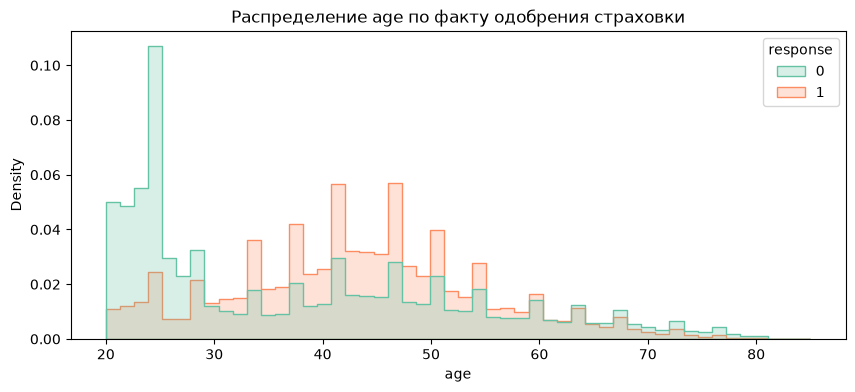

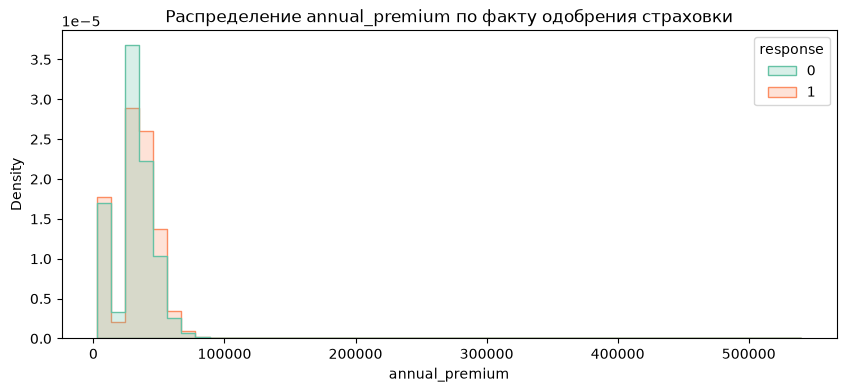

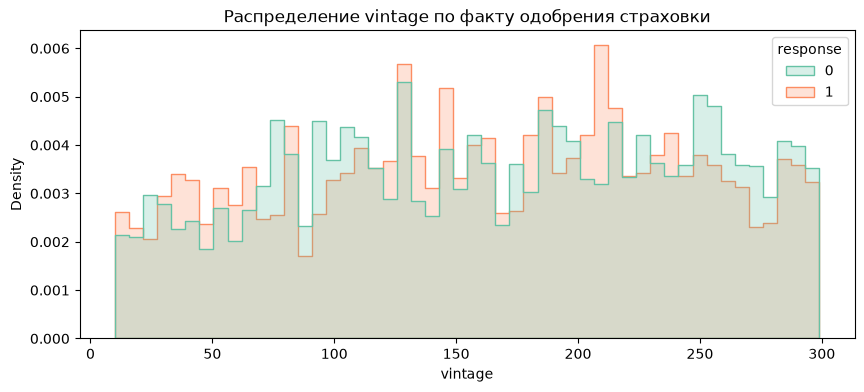

In [ ]:
# посмотрим на распределение
for col in num_cols:
    plt.figure(figsize=(10, 4))

    sns.histplot(
        data=df,
        x=col,
        hue='response',
        stat='density',
        common_norm=False,
        bins=50,
        element='step'
    )

    plt.title(f'Распределение {col} по факту покупки страховки')
    plt.show()

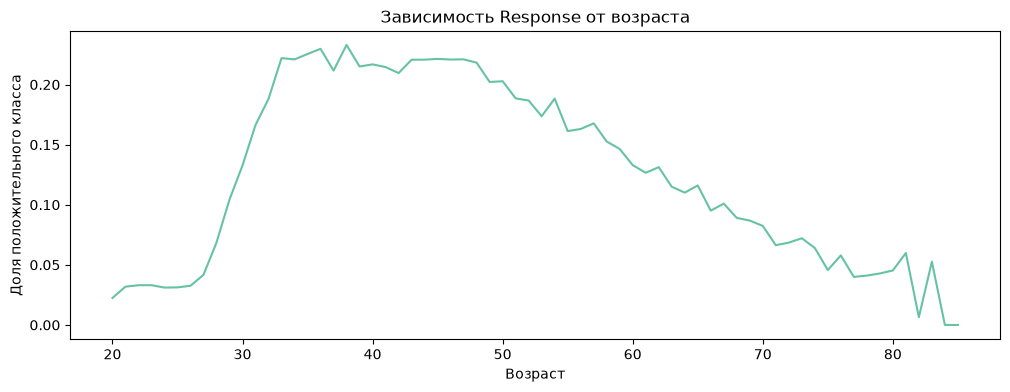

In [ ]:
# подробнее посмотрим на зависимость покупки страховки от возраста
df.groupby('age')['response'].mean().plot(figsize=(12, 4))

plt.title('Зависимость Response от возраста')
plt.xlabel('Возраст')
plt.ylabel('Доля положительного класса')
plt.show()

In [ ]:
# разобьем возраст на бакеты и посмотрим долю клиентов с купленной страховкой
age_groups = pd.cut(
    df['age'],
    bins=[19, 29, 39, 49, 59, 69, 85]
)

df.groupby(age_groups, observed=True)['response'].mean()

age
(19, 29]    0.037581
(29, 39]    0.203849
(39, 49]    0.216828
(49, 59]    0.176013
(59, 69]    0.112040
(69, 85]    0.061948
Name: response, dtype: float64

In [36]:
# аналогично посмотрим размер страховой премии
age_groups = pd.cut(
    df['annual_premium'],
    bins=10
)

df.groupby(age_groups, observed=True)['response'].mean()

annual_premium
(2092.465, 56383.5]     0.121631
(56383.5, 110137.0]     0.157950
(110137.0, 163890.5]    0.163399
(163890.5, 217644.0]    0.064815
(217644.0, 271397.5]    0.284173
(271397.5, 325151.0]    0.182039
(325151.0, 378904.5]    0.218750
(378904.5, 432658.0]    0.120482
(432658.0, 486411.5]    0.411765
(486411.5, 540165.0]    0.191860
Name: response, dtype: float64

In [37]:
# аналогично посмотрим кол-во дней клиента  в компании
age_groups = pd.cut(
    df['vintage'],
    bins=10
)

df.groupby(age_groups, observed=True)['response'].mean()

vintage
(9.711, 38.9]     0.132110
(38.9, 67.8]      0.153632
(67.8, 96.7]      0.094959
(96.7, 125.6]     0.118406
(125.6, 154.5]    0.143199
(154.5, 183.4]    0.128065
(183.4, 212.3]    0.137777
(212.3, 241.2]    0.126249
(241.2, 270.1]    0.103559
(270.1, 299.0]    0.105604
Name: response, dtype: float64

### Вывод: <br>
1. Переменная annual_premium имеет длинный хвост справа (правосторонняя ассимметрия) и содержит много выбросов. Возможно имеет смысл взять 0.99 квантиль, чтобы уменьшить влияние экстремальных значений на обучение модели. Однако среди клиентов, размер страховой премии которых превышает 0.99 квантиль, доля купивших страховку составляет 15,5%, что выше среднего значения по выборке (12,3%). На данном этапе удалять выбросы не будем, чтобы не потерять потенциально полезную информацию. 
2. Наблюдаем правостороннюю асимметрию у age и annual_premium, а также незначительную левостороннюю ассимметрию у vintage.
3. Наблюдаем нелинейную зависимость целевой переменной от возраста клиента. Наибольшая доля клиентов, купивших страховку, наблюдается среди клиентов в возрасте от 40 до 49 лет и составляет 21,68%. Среди клиентов от 20 до 29 лет доля купивших страховку составляет только 3,76%. После 49 лет доля заинтересованных клиентов постепенно снижается.

[Вернуться к навигации](#9th)

## <a class="anchor" id="4th"></a> 4. Анализ категоральных переменных

In [38]:
cat_cols = [
    'gender',              # пол
    'driving_license',     # наличие водительского удостоверения
    'previously_insured',  # была ли раньше страховка
    'vehicle_age',         # возраст автомобиля
    'vehicle_damage',      # был ли поврежден авто в прошлом
    'region_code',         # код региона проживания клиента
    'policy_sales_channel' # канал продажи страховки
]

In [39]:
# посмотрим на количество наблюдений в каждой категории
# для региона и кода канала продажи возьмем первые 10 записей
for col in cat_cols:
    print(col)
    print(df[col].value_counts().head(10))
    print()

gender
gender
Male      5686812
Female    4817986
Name: count, dtype: int64

driving_license
driving_license
1    10483993
0       20805
Name: count, dtype: int64

previously_insured
previously_insured
0    5641444
1    4863354
Name: count, dtype: int64

vehicle_age
vehicle_age
1-2 Year     5462483
< 1 Year     4605794
> 2 Years     436521
Name: count, dtype: int64

vehicle_damage
vehicle_damage
Yes    5280779
No     5224019
Name: count, dtype: int64

region_code
region_code
28.0    3150764
8.0      932185
46.0     527921
41.0     508979
15.0     368834
30.0     335220
29.0     308722
50.0     276064
11.0     254092
36.0     239166
Name: count, dtype: int64

policy_sales_channel
policy_sales_channel
152.0    3804105
26.0     2222020
124.0    2067342
160.0     584816
156.0     289345
122.0     259369
157.0     183225
154.0     155215
151.0     101974
163.0      77688
Name: count, dtype: int64



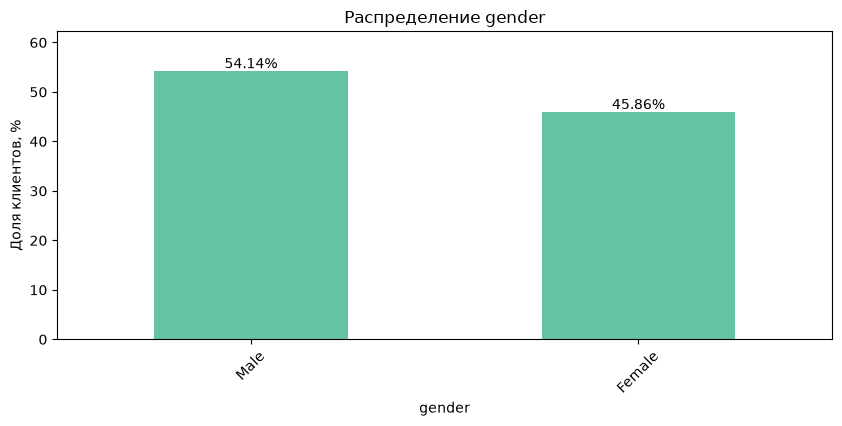

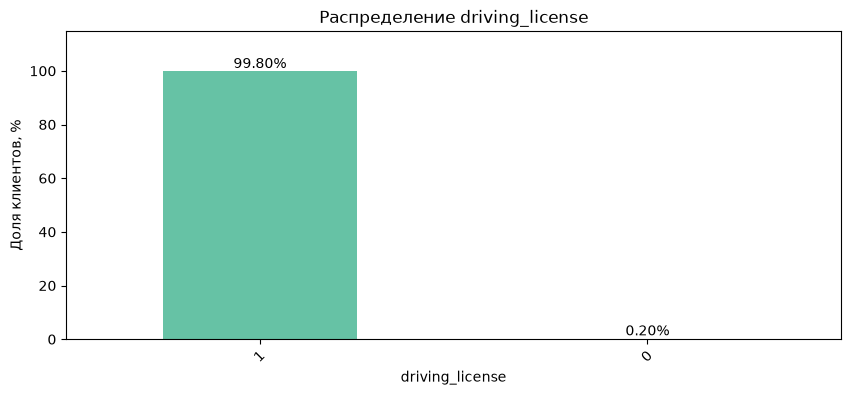

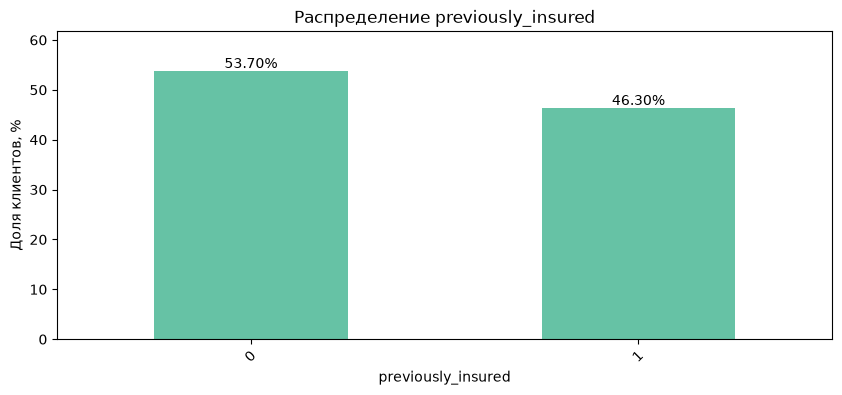

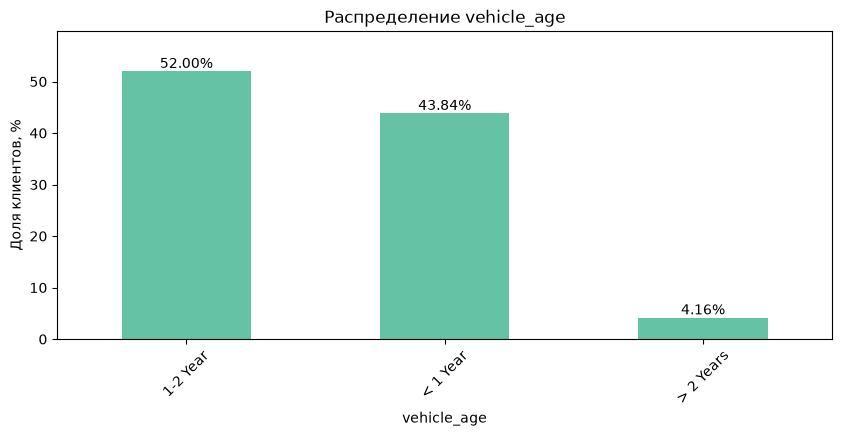

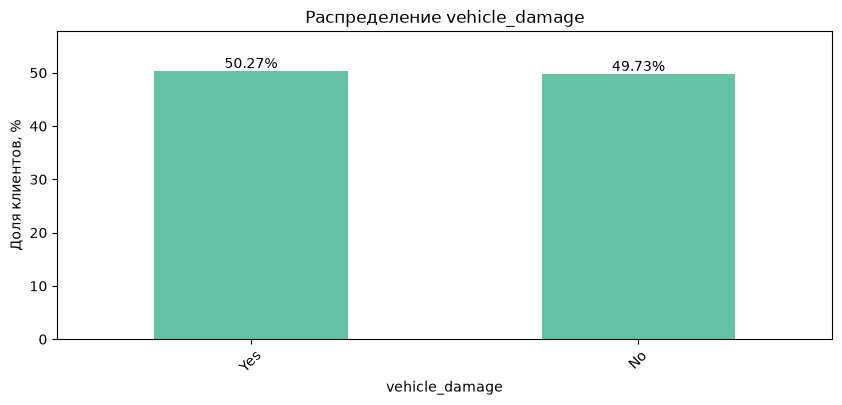

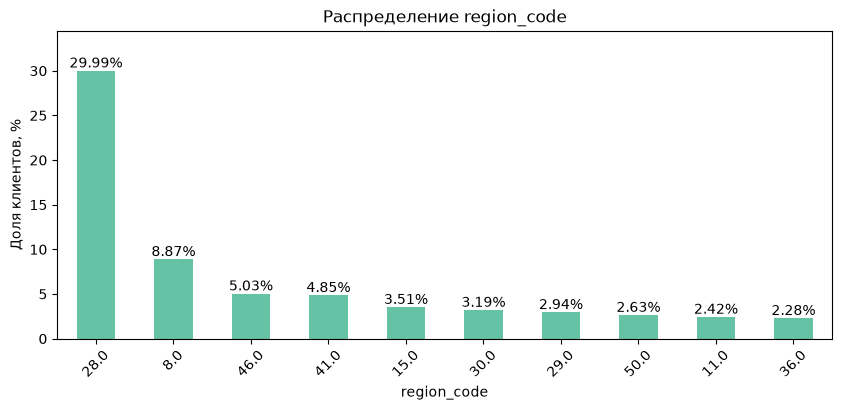

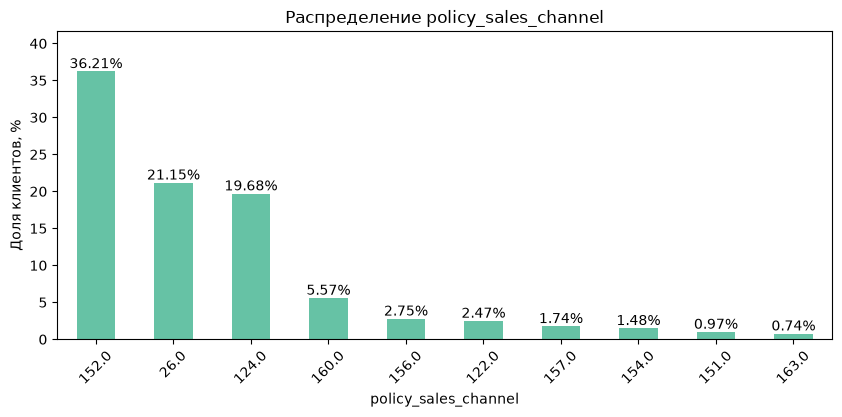

In [ ]:
# посмотрим на распределения (кто чаще покупает страховку)
# для региона и кода канала продажи возьмем первые 10 записей
for col in cat_cols:
    plt.figure(figsize=(10, 4))

    percentages = df[col].value_counts(normalize=True) * 100

    ax = percentages.head(10).plot(kind='bar')

    ax.bar_label(ax.containers[0], fmt='%.2f%%')

    plt.title(f'Распределение {col}')
    plt.ylabel('Доля клиентов, %')
    plt.xticks(rotation=45)
    plt.ylim(0, percentages.max() * 1.15)
    plt.show()

#### Посмотрим на зависимость категориальных признаков от целевой переменной

In [ ]:
# посмотрим на среднее значение покупки страховки по категориям
for col in cat_cols:
    print(col)

    print(
        df.groupby(col)['response']
        .mean()
        .sort_values(ascending=False)
        .round(4)
    )

    print()

gender
gender
Male      0.1397
Female    0.1033
Name: response, dtype: float64

driving_license
driving_license
1    0.1232
0    0.0546
Name: response, dtype: float64

previously_insured
previously_insured
0    0.2285
1    0.0006
Name: response, dtype: float64

vehicle_age
vehicle_age
> 2 Years    0.2991
1-2 Year     0.1778
< 1 Year     0.0414
Name: response, dtype: float64

vehicle_damage
vehicle_damage
Yes    0.2406
No     0.0042
Name: response, dtype: float64

region_code
region_code
28.0    0.1918
38.0    0.1909
51.0    0.1861
19.0    0.1672
4.0     0.1576
23.0    0.1553
24.0    0.1453
18.0    0.1302
7.0     0.1271
3.0     0.1270
39.0    0.1217
40.0    0.1217
35.0    0.1213
29.0    0.1169
41.0    0.1141
52.0    0.1128
5.0     0.1118
20.0    0.1092
11.0    0.1080
45.0    0.1076
1.0     0.1033
12.0    0.1003
31.0    0.0990
46.0    0.0962
33.0    0.0957
48.0    0.0933
43.0    0.0909
13.0    0.0887
8.0     0.0878
42.0    0.0875
14.0    0.0853
32.0    0.0842
47.0    0.0831
9.0     0.080

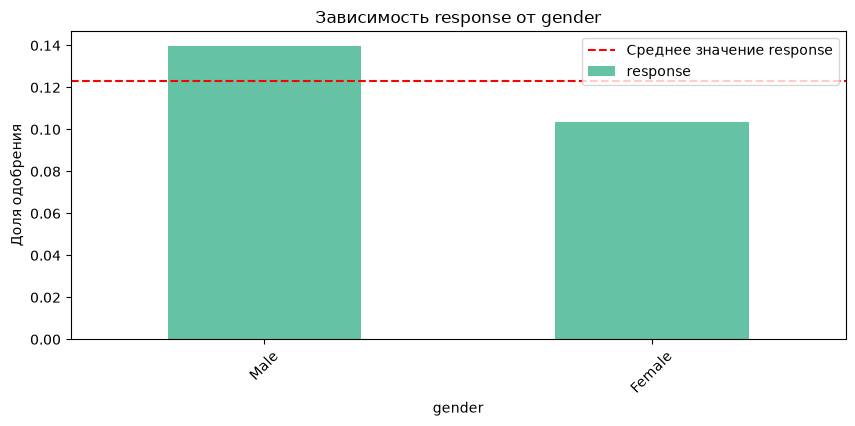

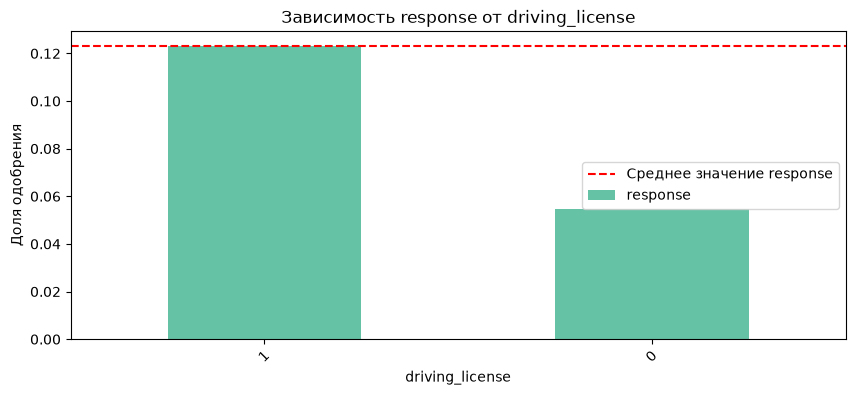

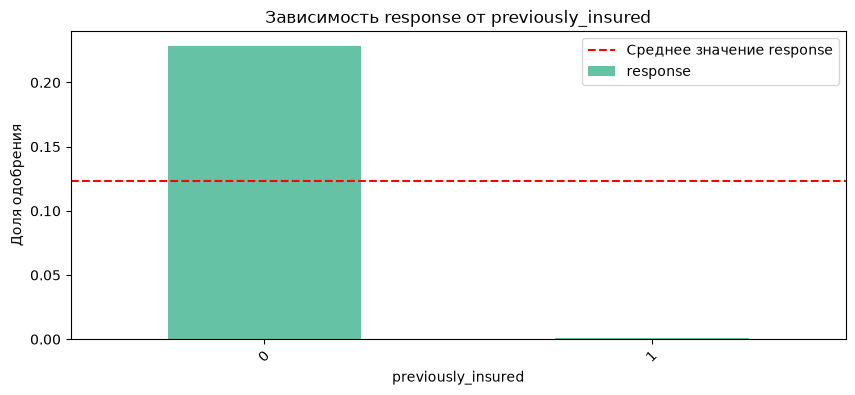

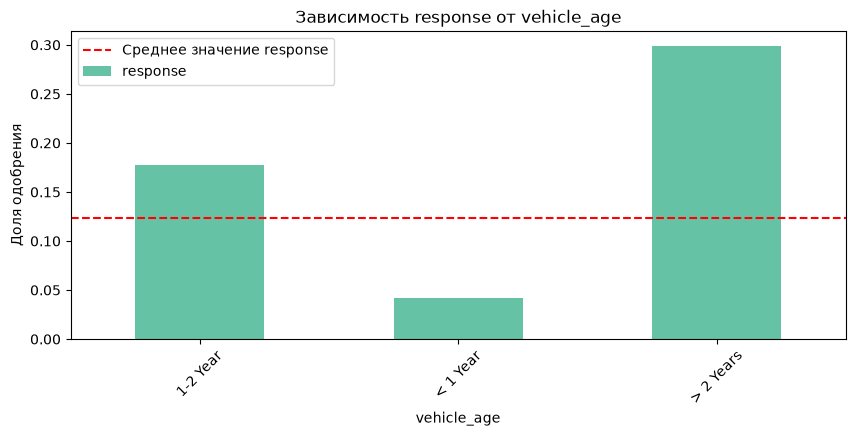

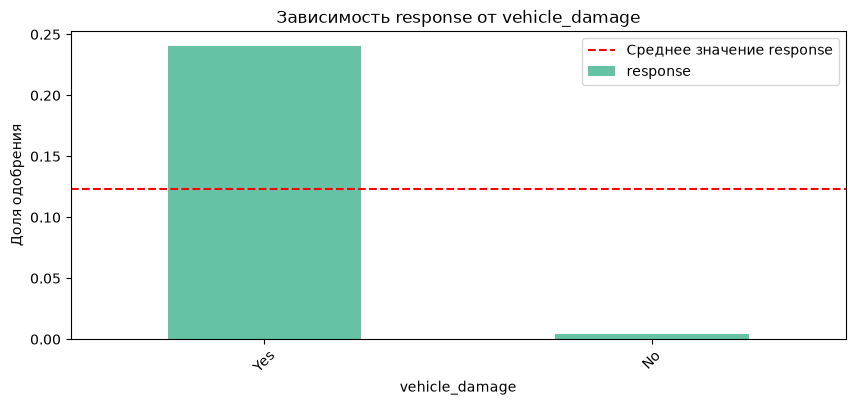

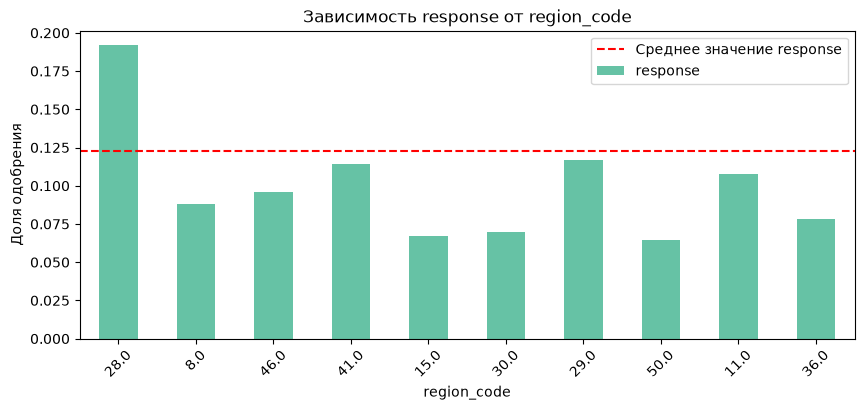

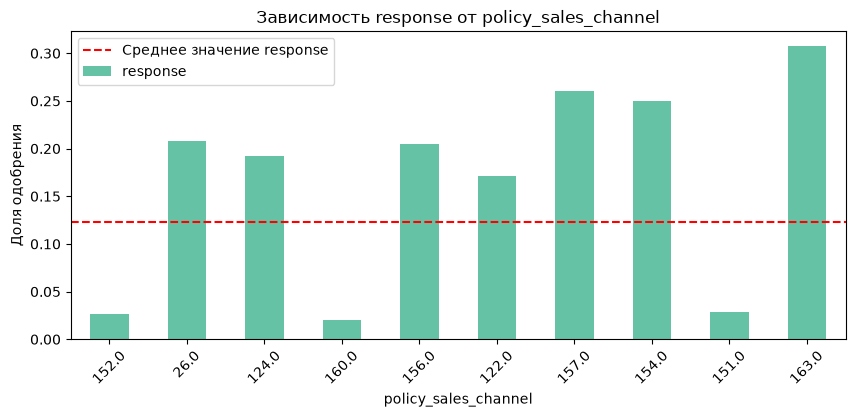

In [ ]:
for col in cat_cols:
    plt.figure(figsize=(10, 4))

    categories = df[col].value_counts().head(10).index

    df.groupby(col)['response'].mean().loc[categories].plot(
        kind='bar'
    )

    plt.axhline(
        df['response'].mean(),
        color='red',
        linestyle='--',
        label='Среднее значение response'
    )

    plt.title(f'Зависимость response от {col}')
    plt.ylabel('Доля купивших страховку')
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

### Вывод: <br>
1. Про распределения категориальных признаков:
- Мужчины составляют 54,14% выборки, женщины - 45,86%.
- У 99,80% клиентов есть водительское удостоверение. Признак driving_license имеет сильный дисбаланс категорий.
- У 46,30% клиентов автомобиль уже был застрахован.
- Наиболее распространённый возраст автомобиля — от 1 до 2 лет.
- Примерно у половины клиентов автомобиль ранее был повреждён.
- Наиболее распространённый регион имеет код 28, на него приходится около 30% наблюдений.
- Наиболее распространённые каналы продаж имеют коды 152, 26 и 124. Вместе они составляют около 77% выборки.
2. Про зависимость категориальных признаков от целевой переменной:
- Мужчины несколько чаще проявляют заинтересованность в покупке страховки, чем женщины.
- Клиенты с водительским удостоверением чаще заинтересованы в страховке. Однако категория клиентов без удостоверения очень малочисленна.
- Наличие ранее оформленной страховки сильно связано с целевой переменной. Клиенты, уже имеющие страховку, практически не заинтересованы в приобритении новой страховки.
- С увеличением возраста автомобиля растёт доля клиентов, заинтересованных в страховке.
- Клиенты, автомобили которых ранее были повреждены, значительно чаще заинтересованы в приобритении страховки.
- Доля купивших страховку различается между регионами. В наиболее распространённом регионе с кодом 28 она составляет примерно 19%, что выше среднего по выборке.
- Несмотря на то, что канал 152 является наиболее распространённым, доля заинтересованных клиентов в нём составляет всего около 3%. Канал продаж может быть информативным признаком для модели.

[Вернуться к навигации](#9th)

## <a class="anchor" id="5th"></a> 5. Корреляционный анализ и взаимосвязь признаков

Посмотрим на корреляцию между признаками (числовыми и бинарными, категориальные не трогаем) с помощью корреляции Пирсона

In [43]:
corr_cols = [
    'age',
    'annual_premium',
    'vintage',
    'driving_license',
    'previously_insured',
    'response'
]

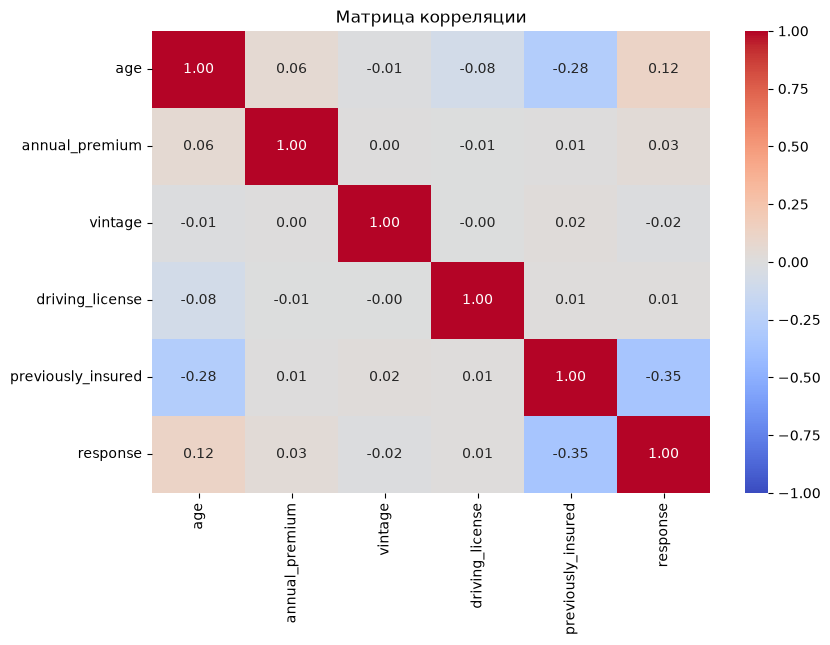

In [44]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Матрица корреляции')
plt.show()

Посмотрим матрицу Крамера для проверки корреляции между категориальными признаками

In [45]:
cat_cols_resp = cat_cols + ['response']

cramer_matrix = pd.DataFrame(
    index=cat_cols_resp,
    columns=cat_cols_resp,
    dtype=float
)

for col1 in cat_cols_resp:
    for col2 in cat_cols_resp:
        table = pd.crosstab(df[col1], df[col2])

        cramer_matrix.loc[col1, col2] = association(
            table,
            method='cramer'
        )

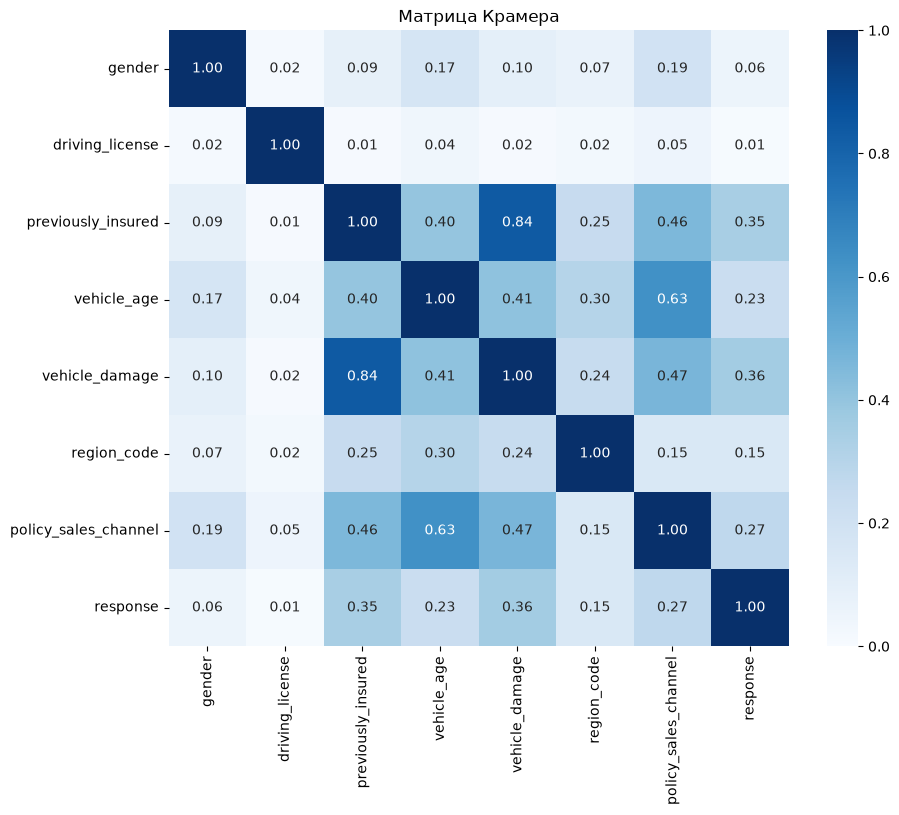

In [46]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cramer_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    vmin=0,
    vmax=1
)

plt.title('Матрица Крамера')
plt.show()

Посмотрим на корреляционное отношение (эта) между категориальными и числовыми признаками. Оно показывает, насколько различия между категориями объясняют разброс значений числового признака

In [ ]:
eta_matrix = pd.DataFrame(
    index=cat_cols,
    columns=num_cols,
    dtype=float
)

for cat in cat_cols:
    for num in num_cols:
        groups = df.groupby(cat, observed=True)[num]

        counts = groups.count()
        means = groups.mean()

        total_mean = df[num].mean()

        numerator = (counts * (means - total_mean)**2).sum()
        denominator = ((df[num] - total_mean)**2).sum()

        eta_matrix.loc[cat, num] = np.sqrt(
            numerator / denominator
        )

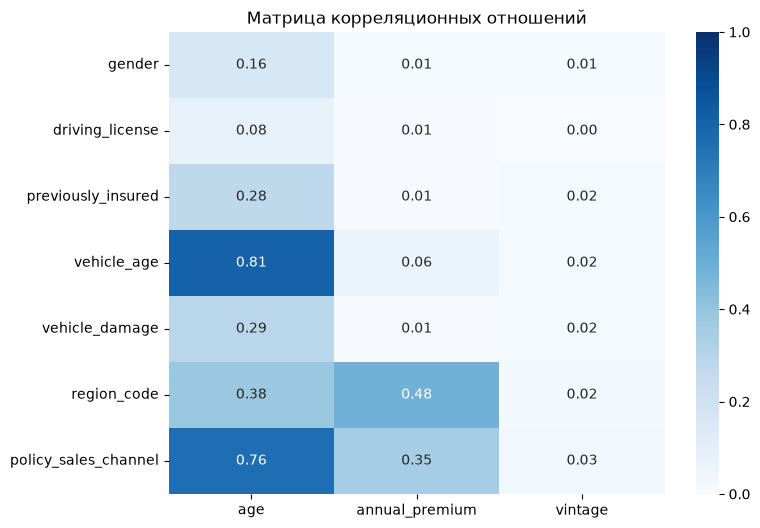

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    eta_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    vmin=0,
    vmax=1
)

plt.title('Матрица корреляционных отношений')
plt.show()

### Вывод: <br>
1. Корреляционная матрица:
- Наблюдаем небольшую отрицательную корреляцию покупки страховки с наличием ранее оформленной страховки (при увеличении одной переменной уменьшается другая)
- Наблюдаем небольшую положительную корреляцию покупки страховки с возрастом (при увеличении одной переменной увеличивается другая)
- Корреляция покупки страховки с остальными признаками незначительная
2. Матрица Крамера:
- Между признаками previously_insured и vehicle_damage наблюдаем выраженная зависимость (V = 0.84).
- Также обнаружена сильная связь между vehicle_age и policy_sales_channel (V = 0.63).
- На данном этапе исключать взаимосвязанные признаки не будем, поскольку каждый из них может содержать дополнительную информацию для модели.
3. Матрица корреляционных отношений:
- Наиболее выраженную связь наблюдаем между возрастом клиента и возрастом автомобиля (0.81), а также между возрастом клиента и каналом продажи страховки (0.76).
- Кроме таого наблюдаем свящт между кодом региона и размером годовой страховой премии (0.48).
- Сильной связи категориальных переменных с количеством дней обслуживания клиента в страховой компании не обнаружено.

[Вернуться к навигации](#9th)

## <a class="anchor" id="6th"></a> 6. Проверка статистических гипотез

### 6.1. Связь отдельных признаков с Response

Для каждого признака проверяем независимость от `response` χ²-тестом. Для числовых признаков тест использует интервалы, поэтому он учитывает и немонотонные различия между группами. Поправку Холма применяем к десяти p-value вместе.

Размер связи оцениваем отдельно. Для категориальных и бинарных признаков используем **V Крамера** на той же таблице сопряжённости (от 0 до 1, без направления). Редкие коды региона и канала объединяем, если ожидаемая частота в меньшем классе ниже 5. Для числовых признаков считаем **Cohen’s d** на исходных значениях: из среднего при `response = 1` вычитаем среднее при `response = 0` и делим на объединённое стандартное отклонение двух групп. Знак показывает направление сдвига, модуль — его размер в стандартных отклонениях. V Крамера и Cohen’s d читаем по отдельности.

Итоговая таблица показывает скорректированное p-value и размер эффекта для каждого признака. Прочерк отмечает меру, которая к данному типу признака не применяется.

In [ ]:
# Проверяем все 10 признаков в одной таблице.
alpha = 0.05
target = df['response']
premium_minimum = df['annual_premium'].eq(df['annual_premium'].min())
premium_group = pd.qcut(df.loc[~premium_minimum, 'annual_premium'], 10, duplicates='drop')
premium_group = premium_group.astype('object').reindex(df.index).fillna('Минимум')

features = {
    'gender': df['gender'],
    'age': pd.cut(df['age'], [19, 29, 39, 49, 59, 69, 85]),
    'driving_license': df['driving_license'],
    'region_code': df['region_code'],
    'previously_insured': df['previously_insured'],
    'vehicle_age': df['vehicle_age'],
    'vehicle_damage': df['vehicle_damage'],
    'annual_premium': premium_group,
    'policy_sales_channel': df['policy_sales_channel'],
    'vintage': pd.cut(df['vintage'], 10),
}

min_class_share = target.value_counts(normalize=True).min()
rows = []
for name, groups in features.items():
    table = target.groupby([groups, target], observed=True).size().unstack(fill_value=0)
    if name in ['region_code', 'policy_sales_channel']:
        expected_min = table.sum(axis=1) * min_class_share
        rare = expected_min < 5
        if rare.any():
            other = table.loc[rare].sum().to_frame().T
            other.index = ['Прочие']
            table = pd.concat([table.loc[~rare], other])
    chi2, p, dof, expected = st.chi2_contingency(table, correction=False)
    cramer_v = np.nan
    if name in cat_cols:
        cramer_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    rows.append([name, len(table), chi2, dof, expected.min(), p, cramer_v])

tests = pd.DataFrame(rows, columns=[
    'Признак', 'Групп', 'χ²', 'df', 'Мин. ожид. частота', 'p-value', 'V Крамера'
])
# Поправка Холма. Упорядоченные скорректированные p-value должны возрастать.
tests = tests.sort_values('p-value').reset_index(drop=True)
tests['p-value (Холм)'] = (tests['p-value'] * np.arange(len(tests), 0, -1)).cummax().clip(upper=1)
tests['Значим при α = 0,05'] = np.where(tests['p-value (Холм)'] < alpha, 'Да', 'Нет')

# Cohen’s d: взвешиваем дисперсии групп по числу степеней свободы.
numeric_summary = df.groupby('response')[num_cols].agg(['count', 'mean', 'std'])
n = numeric_summary.xs('count', axis=1, level=1)
means = numeric_summary.xs('mean', axis=1, level=1)
sd = numeric_summary.xs('std', axis=1, level=1)
pooled_sd = np.sqrt(((n - 1) * sd.pow(2)).sum() / (n.sum() - 2))
mean_diff = means.loc[1] - means.loc[0]

numeric_effects = pd.DataFrame({
    'Среднее (Response = 0)': means.loc[0],
    'Среднее (Response = 1)': means.loc[1],
    'Разница средних (1 − 0)': mean_diff,
    'Cohen’s d': mean_diff / pooled_sd,
}).rename_axis('Числовой признак')

tests['Cohen’s d'] = tests['Признак'].map(numeric_effects['Cohen’s d'])
effect_cols = ['Cohen’s d', 'V Крамера']

def format_p(value):
    return '< 1e-300' if value < 1e-300 else f'{value:.2e}'

view = tests.drop(columns=effect_cols).join(tests[effect_cols])
for col in ['p-value', 'p-value (Холм)']:
    view[col] = view[col].map(format_p)
for col in effect_cols:
    view[col] = view[col].map(lambda value: f'{value:.3f}' if pd.notna(value) else '—')
display(view.round({'χ²': 1, 'Мин. ожид. частота': 1}))

,Признак,Групп,χ²,df,Мин. ожид. частота,p-value,p-value (Холм),"Значим при α = 0,05",Cohen’s d,V Крамера
0,gender,2,32040.8,1,592732.4,< 1e-300,< 1e-300,Да,—,0.055
1,age,6,609464.3,5,42828.7,< 1e-300,< 1e-300,Да,0.375,—
2,region_code,53,237589.2,52,209.5,< 1e-300,< 1e-300,Да,—,0.150
3,previously_insured,2,1257236.3,1,598313.8,< 1e-300,< 1e-300,Да,—,0.346
4,vehicle_damage,2,1359666.8,1,642684.6,< 1e-300,< 1e-300,Да,—,0.360
5,vehicle_age,3,561796.7,2,53703.0,< 1e-300,< 1e-300,Да,—,0.231
6,annual_premium,11,59613.1,10,105254.2,< 1e-300,< 1e-300,Да,0.098,—
7,policy_sales_channel,125,775803.3,124,5.9,< 1e-300,< 1e-300,Да,—,0.272
8,vintage,10,29356.7,9,90158.4,< 1e-300,< 1e-300,Да,-0.046,—
9,driving_license,2,905.9,1,2559.5,5.24e-199,5.24e-199,Да,—,0.009


In [ ]:
display(numeric_effects.sort_values('Cohen’s d', key=abs, ascending=False).round(3))

,Среднее (Response = 0),Среднее (Response = 1),Разница средних (1 − 0),Cohen’s d
Числовой признак,,,,
age,37.697,43.276,5.579,0.375
annual_premium,30262.150,31874.421,1612.271,0.098
vintage,164.355,160.648,-3.707,-0.046


**Вывод.** После поправки Холма все 10 признаков статистически значимы. При 10,5 млн наблюдений даже очень слабые связи дают малые p-value. Например, у водительского удостоверения скорректированное p-value ≈ 5,24 × 10⁻¹⁹⁹, а V Крамера — всего **0,009**.

- **Числовые признаки.** Самый заметный сдвиг средних у возраста клиента (**d = +0,375**): покупатели в среднем старше на 5,58 года (43,28 против 37,70). У годовой премии сдвиг мал (**d = +0,098**), у срока обслуживания ещё меньше и направлен в обратную сторону (**d = −0,046**). Cohen’s d описывает разницу средних. По возрастным интервалам связь немонотонна: доля покупок растёт с **3,76%** в 20–29 лет до **21,68%** в 40–49 лет, затем снижается до **6,19%** в 70–85 лет.
- **Категориальные признаки.** Наибольшие V Крамера у истории повреждений (**0,360**), прежней страховки (**0,346**) и канала продаж (**0,272**). Далее идут возраст автомобиля (**0,231**) и регион (**0,150**). Самые слабые связи у пола (**0,055**) и наличия водительского удостоверения (**0,009**).

### 6.2. Как сочетания признаков связаны с Response

Сравниваем три пары. Для первых двух доля сравнивается между клиентами с повреждениями и без них. Для третьей сравниваем каналы 124 и 26 внутри возрастных групп.

**H₀** — разница долей одинакова во всех группах второго признака. **H₁** — хотя бы одна разница отличается. Тест Вальда оценивает взаимодействие на шкале процентных пунктов. Порог для трёх проверок составляет **0,05 / 3 ≈ 0,0167**. Интервалы 95% относятся к отдельным разницам долей.

In [48]:
# В каждой строке показываем два сегмента и разницу долей между ними.
age_band = pd.cut(df['age'], [19, 29, 39, 49, 59, 69, 85],
                 labels=['20–29', '30–39', '40–49', '50–59', '60–69', '70–85'])
comparisons = [
    ('Прежняя страховка × повреждения', df['previously_insured'],
     df['vehicle_damage'], 'No', 'Yes'),
    ('Возраст авто × повреждения', df['vehicle_age'],
     df['vehicle_damage'], 'No', 'Yes'),
    ('Возраст клиента × канал', age_band, df['policy_sales_channel'], 26, 124),
]

effects = []
for name, group, feature, reference, compared in comparisons:
    selected = feature.isin([reference, compared])
    counts = (target[selected].groupby([group[selected], feature[selected]], observed=True)
              .agg(n='size', positive='sum'))
    n = counts['n'].unstack()
    rates = counts['positive'].unstack() / n
    diff = rates[compared] - rates[reference]
    variance = (rates * (1 - rates) / n).sum(axis=1)
    se = np.sqrt(variance)
    pooled_diff = np.average(diff, weights=1 / variance)
    wald = ((diff - pooled_diff)**2 / variance).sum()
    p = st.chi2.sf(wald, len(diff) - 1)

    for level in diff.index:
        effects.append({
            'Комбинация': name, 'Группа': level,
            'Сравнение': f'{compared} − {reference}',
            'n (база)': n.loc[level, reference], 'Доля (база), %': 100 * rates.loc[level, reference],
            'n (сравнение)': n.loc[level, compared], 'Доля (сравнение), %': 100 * rates.loc[level, compared],
            'Разница, п. п.': 100 * diff[level],
            '95% ДИ, п. п.': f'[{100 * (diff[level] - 1.96 * se[level]):.2f}; '
                            f'{100 * (diff[level] + 1.96 * se[level]):.2f}]',
            'p взаимодействия': format_p(p),
        })

effects = pd.DataFrame(effects).set_index(['Комбинация', 'Группа'])
display(effects.round(2))

Сравнение  n (база)  Доля (база), %  n (сравнение)  Доля (сравнение), %  Разница, п. п.   95% ДИ, п. п. p взаимодействия
Комбинация                      Группа                                                                                                                            
Прежняя страховка × повреждения 0          Yes − No    615411            3.34        5026033                25.24           21.90  [21.84; 21.96]         < 1e-300
                                1          Yes − No   4608608            0.03         254746                 0.65            0.62    [0.59; 0.65]         < 1e-300
Возраст авто × повреждения      1-2 Year   Yes − No   1924852            0.70        3537631                27.07           26.37  [26.32; 26.42]         < 1e-300
                                < 1 Year   Yes − No   3298728            0.26        1307066                13.94           13.68  [13.62; 13.74]         < 1e-300
                                > 2 Years  Yes − No       439            3.64         436082                29.94           26.29  [24.53; 28.05]         < 1e-300
Возраст клиента × канал         20–29      124 − 26    111112           10.78          90537                26.60           15.82  [15.48; 16.16]         < 1e-300
                                30–39      124 − 26    225336           27.69         450444                27.44           -0.24  [-0.47; -0.02]         < 1e-300
                                40–49      124 − 26    799865           26.07         829380                19.94           -6.13  [-6.26; -6.00]         < 1e-300
                                50–59      124 − 26    588844           21.06         401587                14.98           -6.08  [-6.24; -5.93]         < 1e-300
                                60–69      124 − 26    340283           12.87         210875                10.01           -2.86  [-3.03; -2.69]         < 1e-300
                                70–85      124 − 26    156580            7.06          84519                 4.47           -2.59  [-2.78; -2.40]         < 1e-300

**Вывод.** Связь повреждений с Response зависит от прежней страховки. Разница долей составляет **+21,90 п. п.** без прежней страховки и **+0,62 п. п.** с ней. Для автомобилей младше года разница составляет **+13,68 п. п.**, а для автомобилей 1–2 лет — **+26,37 п. п.** В группе авто старше двух лет без повреждений мало наблюдений, поэтому её интервал шире. Разрыв канала 124 с каналом 26 положительный у клиентов 20–29 лет и отрицательный у клиентов 40–49 лет.

### 6.3. Дают ли комбинации прирост качества

Обучаем одну и ту же логистическую модель сначала на базовых признаках, затем добавляем индикаторы сочетаний. Базовые признаки — возрастная группа клиента, возраст авто, прежняя страховка, повреждения, канал и регион. Выделяем три крупнейших канала и десять крупнейших регионов в обучающей части, остальные объединяем.

Для сравнения используем **Average Precision (AP)** на последних 1 млн строк основной выборки. Ранее выделенный финальный тест сохраняем для итоговой оценки. AP случайного ранжирования соответствует доле положительного класса.

In [49]:
# Группируем одинаковые профили, чтобы обучать модель на счётчиках.
from scipy.optimize import minimize
from scipy.special import expit

train, valid = df.iloc[:-1_000_000], df.iloc[-1_000_000:]
base_columns = ['age_group', 'vehicle_age', 'previously_insured',
                'vehicle_damage', 'channel', 'region']
top_channels = train['policy_sales_channel'].value_counts().head(3).index
top_regions = train['region_code'].value_counts().head(10).index

def profile_counts(data):
    profiles = data[['vehicle_age', 'previously_insured', 'vehicle_damage', 'response']].copy()
    profiles['age_group'] = age_band.loc[data.index]
    profiles['channel'] = data['policy_sales_channel'].where(data['policy_sales_channel'].isin(top_channels), -1)
    profiles['region'] = data['region_code'].where(data['region_code'].isin(top_regions), -1)
    return (profiles.groupby(base_columns, observed=True)['response']
            .agg(n='size', positive='sum').reset_index())

train_counts, valid_counts = profile_counts(train), profile_counts(valid)
profiles = pd.concat([train_counts, valid_counts], ignore_index=True)
split = len(train_counts)
encoded = {col: pd.get_dummies(profiles[col], drop_first=True, dtype=float).to_numpy()
           for col in base_columns}
base = np.column_stack([np.ones(len(profiles)), *encoded.values()])

def combined_indicators(left, right):
    # Произведения индикаторов выделяют сочетания категорий двух признаков.
    crossed = encoded[left][:, :, None] * encoded[right][:, None, :]
    return crossed.reshape(len(profiles), -1)

combined = {
    'Прежняя страховка × повреждения': combined_indicators('previously_insured', 'vehicle_damage'),
    'Возраст авто × повреждения': combined_indicators('vehicle_age', 'vehicle_damage'),
    'Возраст клиента × канал': combined_indicators('age_group', 'channel'),
}

def validation_ap(x):
    x_train, x_valid = x[:split], x[split:]
    n = train_counts['n'].to_numpy()
    positive = train_counts['positive'].to_numpy()

    def loss(beta):
        score = x_train @ beta
        value = (n * np.logaddexp(0, score) - positive * score).sum() / n.sum()
        gradient = x_train.T @ (n * expit(score) - positive) / n.sum()
        return value, gradient

    fit = minimize(loss, np.zeros(x.shape[1]), jac=True, method='BFGS',
                   options={'gtol': 1e-9, 'maxiter': 1000})
    if np.linalg.norm(fit.jac, ord=np.inf) > 1e-7:
        raise RuntimeError(f'Модель не сошлась: {fit.message}')

    # AP с учётом числа строк и положительных ответов в каждом профиле.
    ranked = (valid_counts.assign(score=x_valid @ fit.x)
              .groupby('score')[['n', 'positive']].sum().sort_index(ascending=False))
    precision = ranked['positive'].cumsum() / ranked['n'].cumsum()
    return (precision * ranked['positive']).sum() / ranked['positive'].sum()

experiments = {'Базовые признаки': [], **{name: [x] for name, x in combined.items()},
               'Все три комбинации': list(combined.values())}
scores = pd.Series({name: validation_ap(np.column_stack([base, *extra]))
                    for name, extra in experiments.items()}, name='Average Precision')
display(pd.DataFrame({'Average Precision': scores,
                      'ΔAP к базовой модели': scores - scores.iloc[0]}).round(5))
print(f'Доля Response = 1 на валидации: {valid.response.mean():.2%}')

,Average Precision,ΔAP к базовой модели
Базовые признаки,0.34899,0.00000
Прежняя страховка × повреждения,0.34898,-0.00001
Возраст авто × повреждения,0.34888,-0.00011
Возраст клиента × канал,0.35246,0.00347
Все три комбинации,0.35239,0.00340


Доля Response = 1 на валидации: 12.24%


**Вывод.** Лучший результат дала комбинация **«возрастная группа клиента × канал»**. Average Precision вырос с **0.34899 до 0.35246** (ΔAP **+0.00347**). Обе комбинации с повреждениями по отдельности дали небольшое снижение AP. Добавление всех трёх комбинаций уступило лучшей одиночной. Результат относится к этой логистической модели и одному разбиению данных.

### 6.4. Доля Response = 1 по интервалам числовых признаков

Каждая точка показывает медиану признака в интервале и долю положительных ответов. Размер точки соответствует числу наблюдений. Пунктир показывает среднюю долю по обучающей части. Однофакторные распределения и корреляции уже приведены в разделах 3–5.

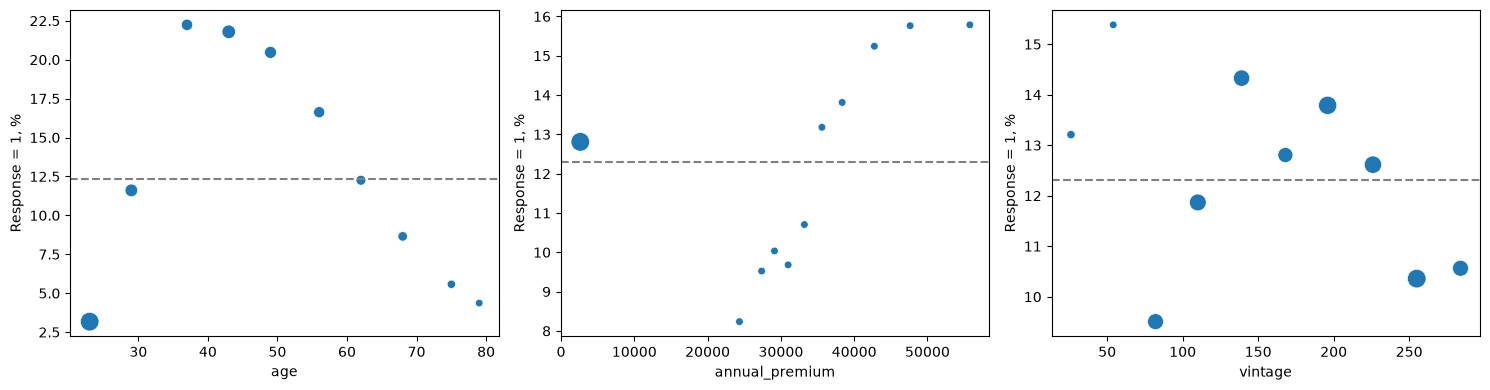

In [50]:
# Доля по интервалам на обучающей части.
eda = train
numeric = ['age', 'annual_premium', 'vintage']

# Scatter plot. Каждая точка — группа, её размер показывает число строк.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric):
    if col == 'annual_premium':
        # Частую минимальную премию выделяем отдельно, остальные делим по квантилям.
        is_min = eda[col].eq(eda[col].min())
        groups = pd.qcut(eda.loc[~is_min, col], 10, duplicates='drop')
        groups = groups.astype('string').reindex(eda.index).fillna('Минимум')
    else:
        groups = pd.cut(eda[col], bins=10)

    points = eda.groupby(groups, observed=True).agg(
        x=(col, 'median'), rate=('response', 'mean'), n=('response', 'size')
    ).sort_values('x')

    sns.scatterplot(data=points, x='x', y=points['rate'] * 100,
                    size='n', sizes=(30, 180), legend=False, ax=ax)
    ax.axhline(100 * eda['response'].mean(), color='grey', linestyle='--')
    ax.set(xlabel=col, ylabel='Response = 1, %')

plt.tight_layout()
plt.show()

### 6.5. Попарные scatter-графики признаков

Показываем все 45 уникальных пар из 10 признаков (3 числовые пары, 21 смешанная и 21 категориальная) на одной случайной подвыборке из 25 000 строк (`random_state=42`). В числовых и смешанных парах цвет точки показывает `response`, а в смешанных парах небольшой сдвиг по оси категорий уменьшает наложение. Годовая премия показана в логарифмическом масштабе. Для двух категориальных признаков пузырёк соответствует сочетанию категорий: размер растёт с числом наблюдений, цвет показывает долю покупок. Серые пузырьки отмечают сочетания с менее чем 30 наблюдениями.

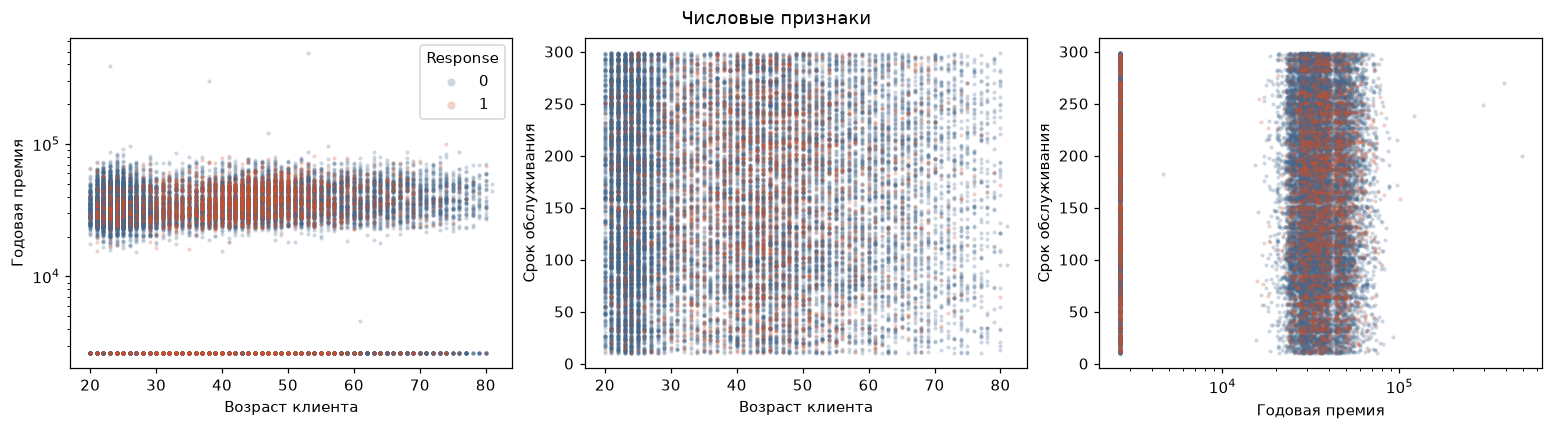

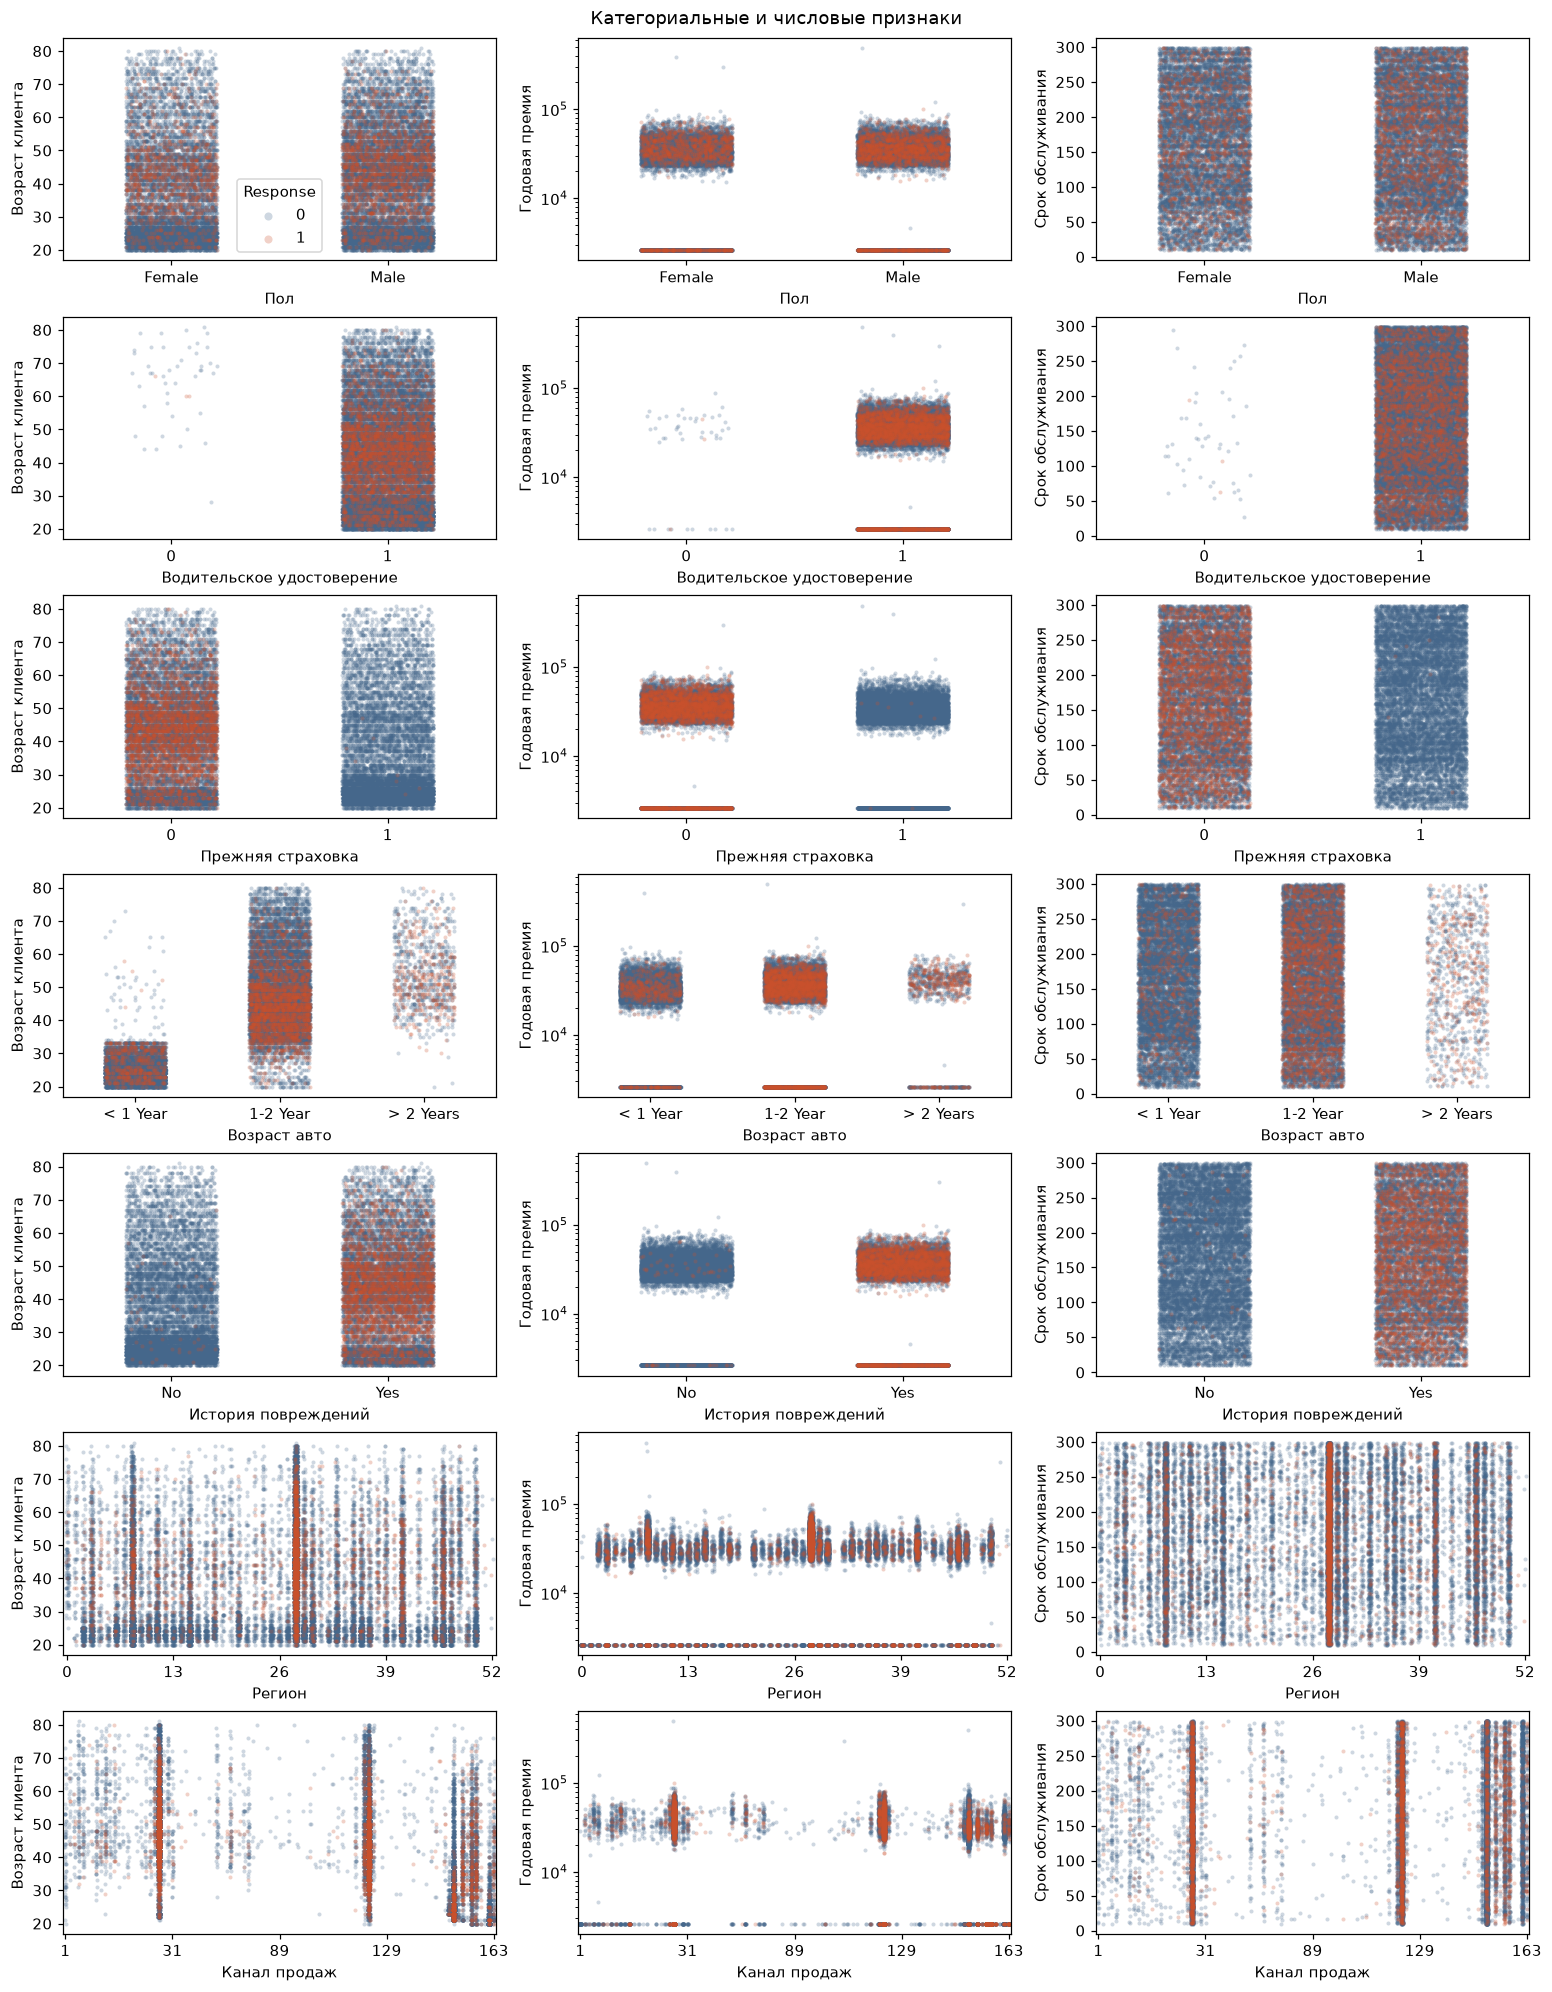

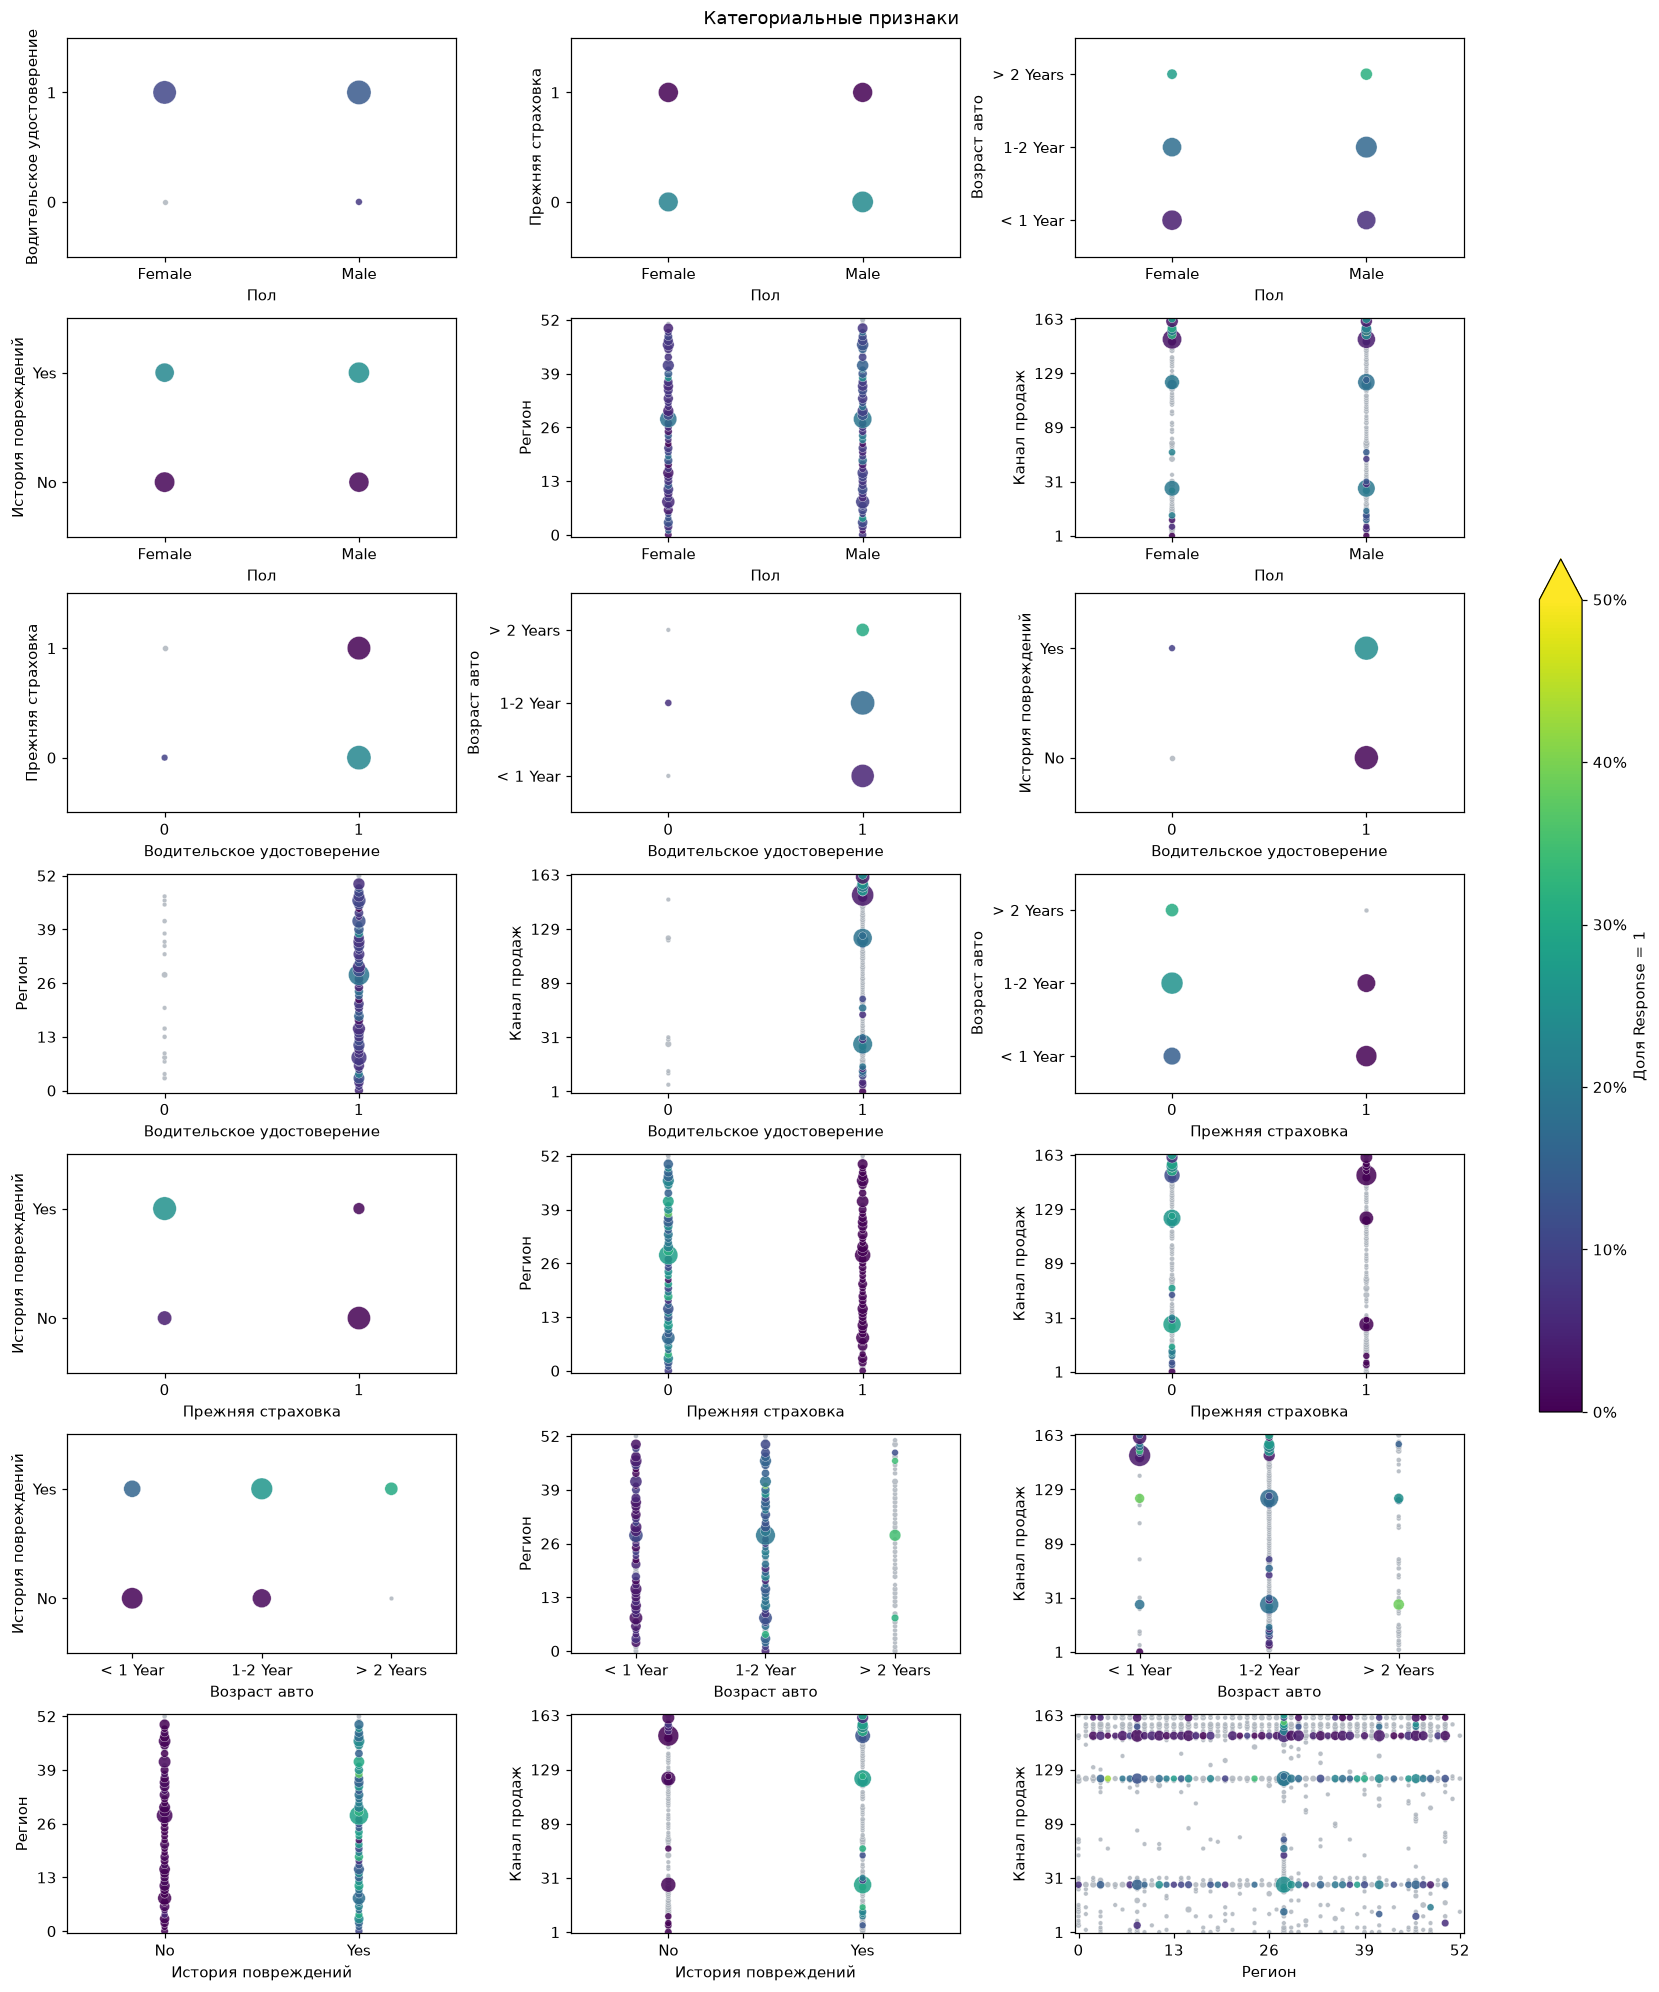

In [ ]:
from itertools import combinations
from matplotlib.colors import Normalize

scatter_sample = df.sample(n=min(25_000, len(df)), random_state=42)[
    num_cols + cat_cols + ['response']
].copy()
category_levels = {}
for col in cat_cols:
    levels = sorted(scatter_sample[col].dropna().unique())
    if col == 'vehicle_age':
        levels = [level for level in ['< 1 Year', '1-2 Year', '> 2 Years']
                  if level in levels]
    category_levels[col] = levels
    scatter_sample[col] = pd.Categorical(scatter_sample[col], categories=levels).codes
    scatter_sample[col] = scatter_sample[col].where(scatter_sample[col].ge(0))

labels = {
    'age': 'Возраст клиента', 'annual_premium': 'Годовая премия',
    'vintage': 'Срок обслуживания', 'gender': 'Пол',
    'driving_license': 'Водительское удостоверение', 'region_code': 'Регион',
    'previously_insured': 'Прежняя страховка', 'vehicle_age': 'Возраст авто',
    'vehicle_damage': 'История повреждений', 'policy_sales_channel': 'Канал продаж',
}
jitter = np.random.default_rng(42).uniform(-0.21, 0.21, len(scatter_sample))
response_palette = {0: '#45678b', 1: '#cb502c'}

def set_pair_axis(axis, col):
    axis.set_label_text(labels[col])
    if col in category_levels:
        levels = category_levels[col]
        ticks = np.linspace(0, len(levels) - 1, min(5, len(levels)), dtype=int)
        tick_labels = [f'{levels[i]:g}' if isinstance(levels[i], (float, np.floating))
                       else str(levels[i]) for i in ticks]
        axis.set_ticks(ticks, labels=tick_labels)
        return -0.5, len(levels) - 0.5
    return None

def label_pair(ax, x, y):
    for col, axis, set_limits, set_scale in [
        (x, ax.xaxis, ax.set_xlim, ax.set_xscale),
        (y, ax.yaxis, ax.set_ylim, ax.set_yscale),
    ]:
        limits = set_pair_axis(axis, col)
        if limits is not None:
            set_limits(limits)
        if col == 'annual_premium':
            set_scale('log')

def draw_observations(ax, x, y):
    x_values = scatter_sample[x] + jitter if x in category_levels else scatter_sample[x]
    for response, color in response_palette.items():
        group = scatter_sample['response'].eq(response)
        ax.scatter(x_values[group], scatter_sample.loc[group, y], label=str(response),
                   s=7, alpha=0.26, color=color, linewidths=0)
    label_pair(ax, x, y)

numeric_pairs = list(combinations(num_cols, 2))
fig, axes = plt.subplots(1, len(numeric_pairs), figsize=(14, 3.8), layout='constrained')
for ax, (x, y) in zip(axes, numeric_pairs):
    draw_observations(ax, x, y)
axes[0].legend(title='Response', markerscale=2)
fig.suptitle('Числовые признаки')
plt.show()

fig, axes = plt.subplots(len(cat_cols), len(num_cols),
                         figsize=(14, 18), layout='constrained')
for x, row in zip(cat_cols, axes):
    for y, ax in zip(num_cols, row):
        draw_observations(ax, x, y)
axes[0, 0].legend(title='Response', markerscale=2)
fig.suptitle('Категориальные и числовые признаки')
plt.show()

categorical_pairs = list(combinations(cat_cols, 2))
fig, axes = plt.subplots(len(categorical_pairs) // 3, 3,
                         figsize=(15, 18), layout='constrained')
for ax, (x, y) in zip(axes.flat, categorical_pairs):
    points = (scatter_sample.groupby([x, y])['response']
              .agg(n='size', rate='mean').reset_index())
    enough = points['n'].ge(30)
    for mask, colors in [
        (~enough, {'color': '#aeb5bd'}),
        (enough, {'c': points.loc[enough, 'rate'], 'cmap': 'viridis', 'vmin': 0, 'vmax': 0.5}),
    ]:
        ax.scatter(points.loc[mask, x], points.loc[mask, y],
                   s=7 + 2.1 * np.sqrt(points.loc[mask, 'n']),
                   edgecolors='white', linewidths=0.25, alpha=0.85, **colors)
    label_pair(ax, x, y)

color_scale = plt.cm.ScalarMappable(norm=Normalize(0, 0.5), cmap='viridis')
fig.colorbar(color_scale, ax=axes.ravel(), shrink=0.45, extend='max',
             label='Доля Response = 1', format='{x:.0%}')
fig.suptitle('Категориальные признаки')
plt.show()

**Вывод по графикам.**

- **Возраст клиента × возраст авто / канал продаж.** Медианный возраст клиента — **24 года** для авто младше года, **47 лет** для авто 1–2 лет и **53 года** для авто старше двух лет. У клиентов канала 152 медиана возраста — **24 года**, у каналов 124 и 26 — **45 и 49 лет**. Графики показывают, что возрастной состав этих каналов различается. В п. 6.2 видно, что разница долей покупок между каналами 124 и 26 меняет знак в зависимости от возраста клиента.
- **Прежняя страховка × история повреждений.** Самая высокая доля покупок среди четырёх сочетаний — **25,24%** у клиентов с повреждениями и без прежней страховки. При наличии прежней страховки покупают **менее 1%** клиентов в обеих группах по истории повреждений. Это согласуется с разницей долей в п. 6.2.
- **Числовые пары.** На графиках с годовой премией выделяется полоса на минимуме **2 630**. На это значение приходится **18,36%** основной выборки. Монотонные связи между тремя числовыми признаками слабы (наибольший модуль корреляции Спирмена — **0,107** для возраста и премии).

Числа в выводах посчитаны на всей основной выборке.

[Вернуться к навигации](#9th)